## Q1

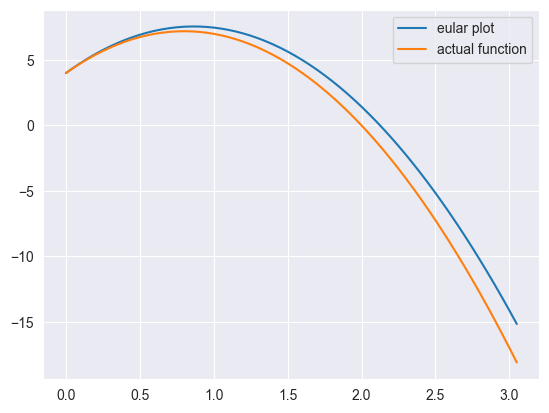

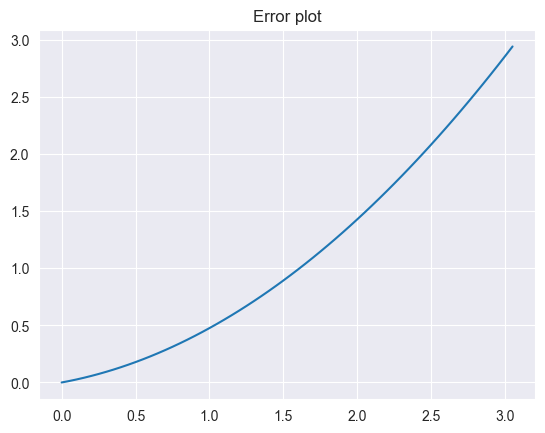

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def f(x,y):
    return (2*y-18*x)/(1+x)
def g(x):
    return -5*(x**2)+8*x+4
x0,y0=0,4
h=0.05
def eular(f,x,y,h):
    X,Y=[x],[y]
    while x<3:
        y=y+h*f(x,y)
        x=x+h
        X.append(x)
        Y.append(y)
    return np.array(X),np.array(Y)
X,Y=eular(f,x0,y0,h)
plt.plot(X,Y,label='eular plot')
plt.plot(X,g(X),label='actual function')
plt.legend()
plt.show()

plt.plot(X,abs(Y-g(X)))
plt.title('Error plot')
plt.show()

## Q2

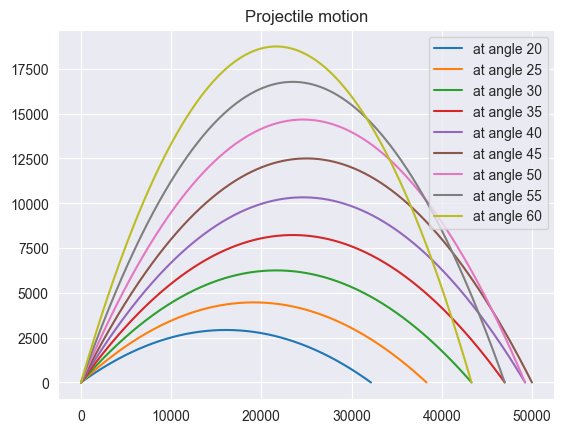

Maximum range will be at angle of 45


In [2]:
g=9.8
v=700
t0=0
x0,y0=0,0

h=0.01
def eular(x,y,t,h,theta):
    z=v*np.sin(theta)
    X,Y=[x],[y]
    while y>=0:
        x=x+h*(v*np.cos(theta))
        y=y+h*z
        z=z+(-g)*h
        t=t+h
        X.append(x)
        Y.append(y)
    return X,Y,x

t=np.arange(20,65,5)
theta=t*np.pi/180

for i in range(len(t)):
    X,Y,_=eular(x0,y0,t0,h,theta[i])
    plt.plot(X,Y,label=f'at angle {t[i]}')
plt.legend()
plt.title('Projectile motion')
plt.show()

# finding the maximum range

t=np.arange(20,65,1)
theta=t*np.pi/180
Range=[]
for i in range(len(t)):
    _,_,z=eular(x0,y0,t0,h,theta[i])
    Range.append(z)
print((f'Maximum range will be at angle of {t[np.argmax(Range)]}')) 

## A different approach

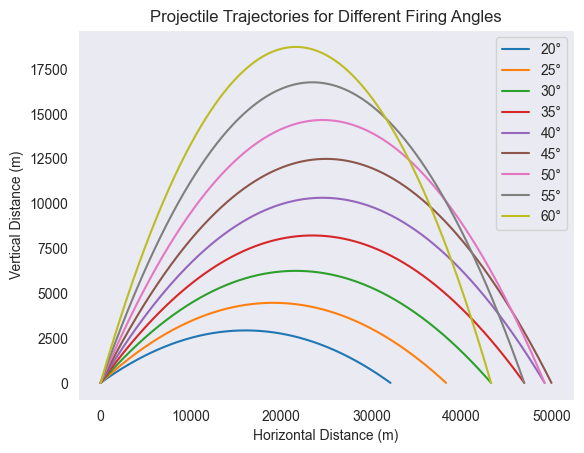

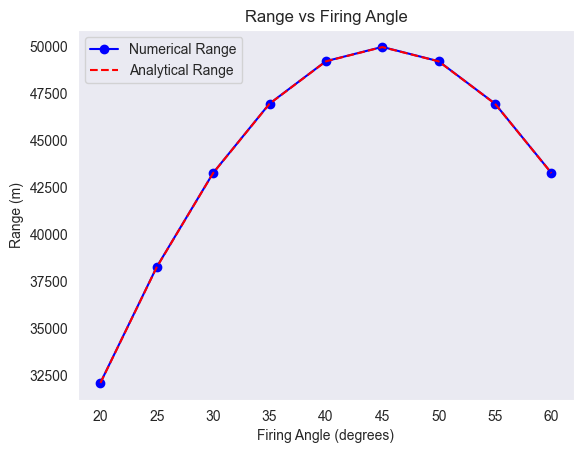

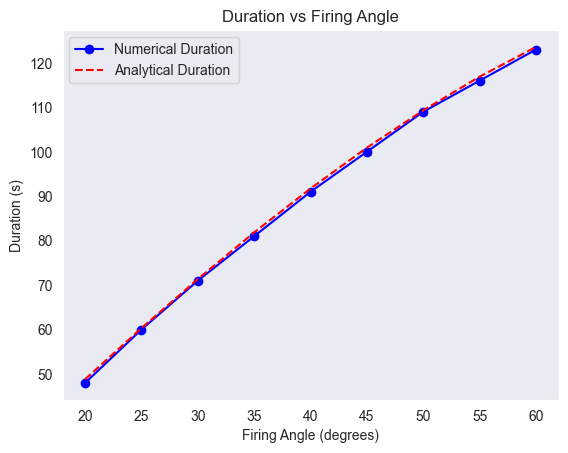

In [3]:
def Eul(f, x0, y0, h, N):
    y = np.zeros(N+1)
    y[0] = y0
    x = x0
    for i in range(1, N+1):
        y[i] = y[i-1] + h * f(x, y[i-1])
        x += h
    return y


v0 = 700  
g = 9.81  
ang = np.arange(20, 65, 5)  
t_r = np.deg2rad(ang)  
h = 0.01  
T = 150  
N = int(T / h) 

ranges = np.zeros_like(ang)
durations = np.zeros_like(ang)

for i, theta in enumerate(t_r):
    
    x0, y0 = 0.0, 0.0
    vx0 = v0 * np.cos(theta)
    vy0 = v0 * np.sin(theta)

    x = np.zeros(N + 1)
    y = np.zeros(N + 1)
    x[0], y[0] = x0, y0
    vx, vy = vx0, vy0

    for j in range(1, N+1):
        x[j] = x[j-1] + h * vx
        y[j] = y[j-1] + h * vy
        vy = vy - h * g 

        if y[j] < 0:
            break

    ranges[i] = x[j]
    durations[i] = j * h

    plt.plot(x[:j+1], y[:j+1], label=f'{ang[i]}°')

plt.xlabel('Horizontal Distance (m)')
plt.ylabel('Vertical Distance (m)')
plt.title('Projectile Trajectories for Different Firing Angles')
plt.legend()
plt.grid()
plt.show()

def analytical_range(theta):
    return (v0**2 * np.sin(2*theta)) / g

def analytical_duration(theta):
    return (2 * v0 * np.sin(theta)) / g

plt.plot(ang, ranges, 'bo-', label='Numerical Range')
plt.plot(ang, analytical_range(t_r), 'r--', label='Analytical Range')
plt.xlabel('Firing Angle (degrees)')
plt.ylabel('Range (m)')
plt.title('Range vs Firing Angle')
plt.legend()
plt.grid()
plt.show()

plt.plot(ang, durations, 'bo-', label='Numerical Duration')
plt.plot(ang, analytical_duration(t_r), 'r--', label='Analytical Duration')
plt.xlabel('Firing Angle (degrees)')
plt.ylabel('Duration (s)')
plt.title('Duration vs Firing Angle')
plt.legend()
plt.grid()
plt.show()


## Q3

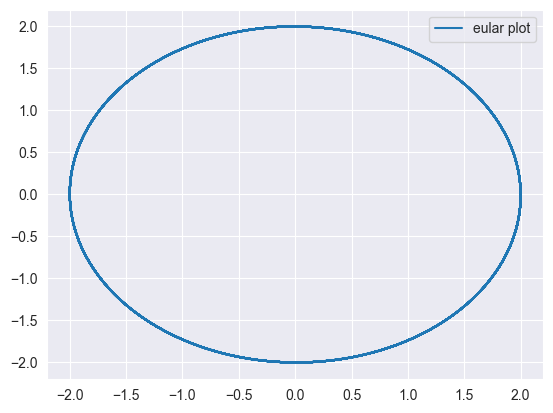

In [15]:

g=10000

x0,z0,t0=2,0,0

def eular(x,z,t,h):
    X,P,T=[x],[z],[t]
    for i in range(g):
        x=x+h*z
        z=z+(-x)*h
        t=t+h
        X.append(x)
        P.append(z)
        T.append(t)
    return X,P,T
X,P,T=eular(x0,z0,t0,0.01)
plt.plot(P,X,label='eular plot')
plt.legend()
plt.show()
        
   



Time period is 6.283199999998695
[  10  100 1000]


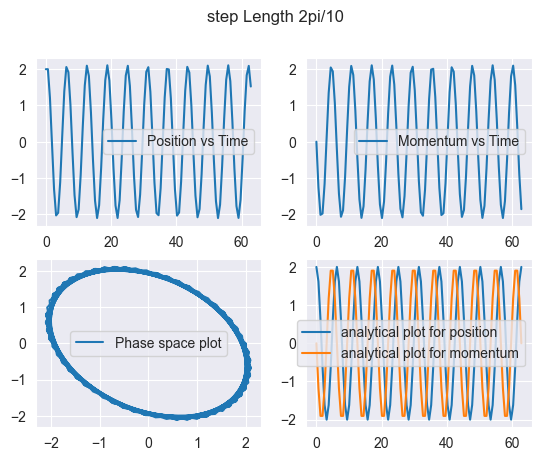

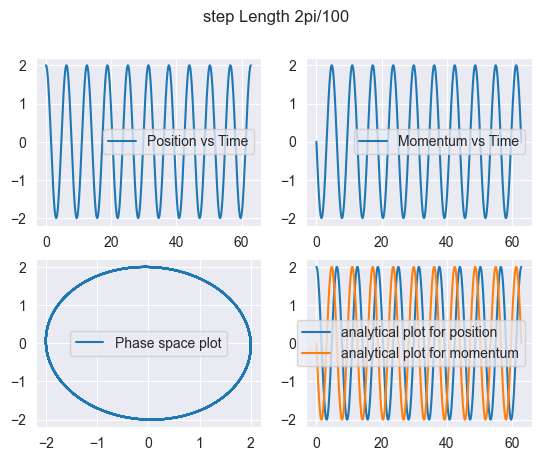

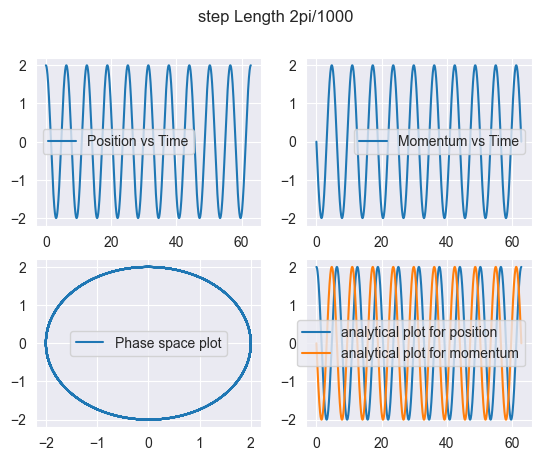

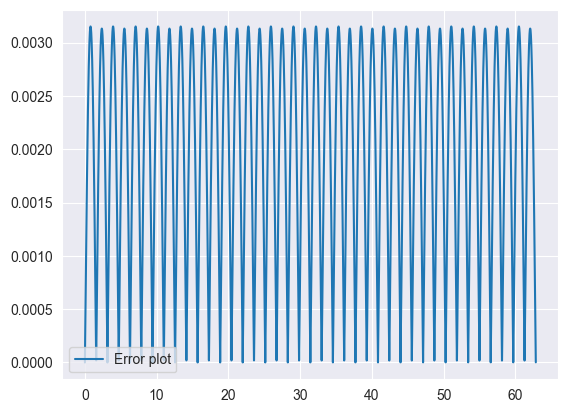

In [5]:

g=10000

x0,z0,t0=2,0,0

def eular(x,z,t,h):
    x=x+h*z
    z=z+(-x)*h
    t=t+h     
    return x,z,t

#determining time period
while x0<=2:
    x0,z0,t0=eular(x0,z0,t0,0.0001)
time_period=t0

print((f'Time period is {time_period}'))   

#2nd part



S=np.array([10,100,1000])
print(S)
H=time_period/S     
for j in range(len(H)):
    x0,z0,t0=2,0,0
    X,P,T=[x0],[z0],[t0]
    for i in range((10*S[j])):
        x0,z0,t0=eular(x0,z0,t0,H[j])
        X.append(x0)
        P.append(z0)
        T.append(t0)
    plt.subplot(2,2,1)
    plt.plot(T,X,label='Position vs Time')
    plt.legend()
    plt.subplot(2,2,2)
    plt.plot(T,P,label='Momentum vs Time')
    plt.legend()
    plt.subplot(2,2,3)
    plt.plot(X,P,label='Phase space plot')
    plt.legend()
    plt.subplot(2,2,4)
    plt.plot(T,2*np.cos(T),label='analytical plot for position')
    plt.plot(T,(-2)*np.sin(T),label='analytical plot for momentum')
    plt.legend()
    plt.suptitle(f'step Length 2pi/{S[j]}')
    plt.show()

#energy calculation
E_analytical=2
P=np.array(P)
T=np.array(T)
X=np.array(X)
E=0.5*((P**2)+(X**2))
plt.plot(T,(abs(E-E_analytical))/E_analytical,label='Error plot')
plt.legend()
plt.show()



## Q4

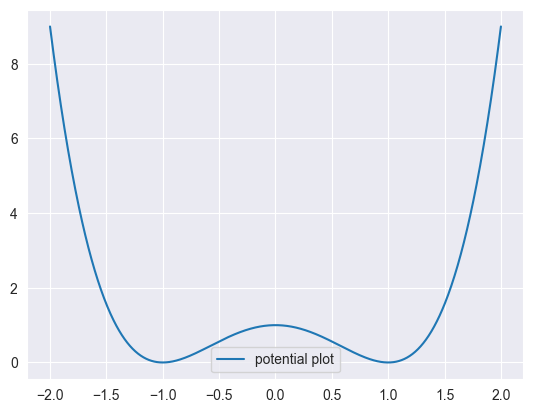

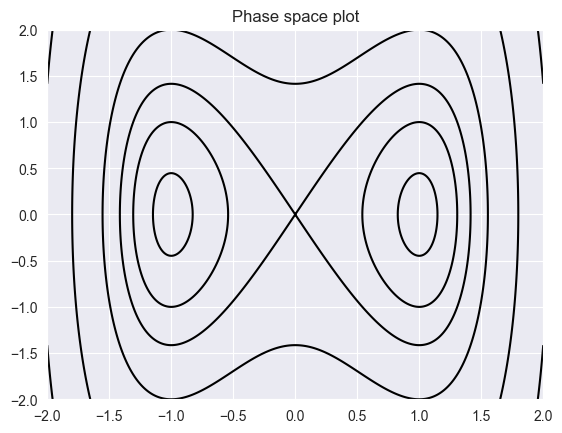

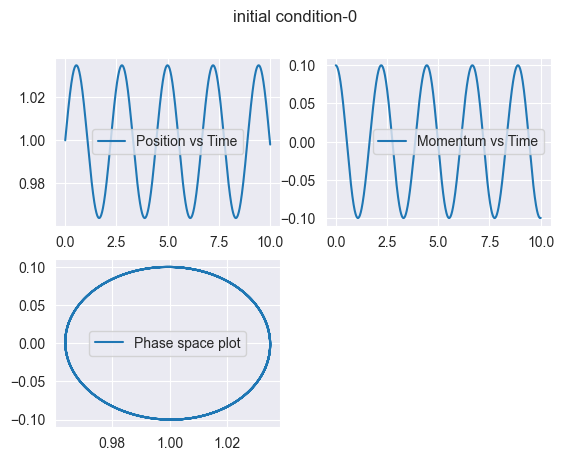

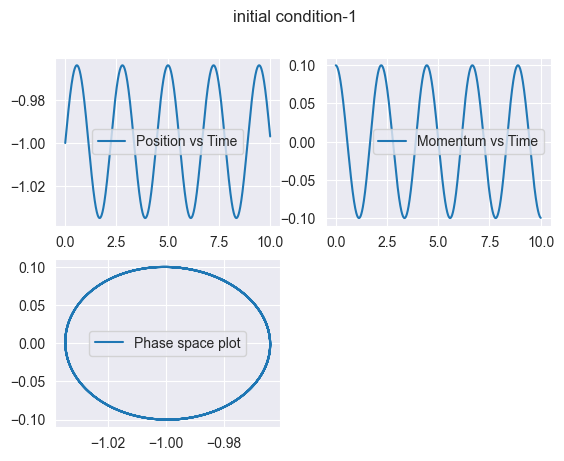

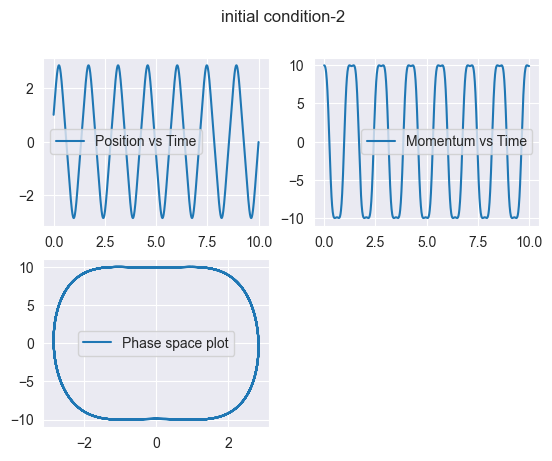

In [6]:
def V(x):
    return (x**2 - 1)**2

def P(x, E):
    return np.sqrt(2 * abs(E - V(x)))

def f(x):
    return -4*x*(x**2 - 1)

X=np.linspace(-2,2,1000)
P=np.linspace(-2,2,1000)
plt.plot(X,V(X),label='potential plot')
plt.legend()
plt.show()
X,P=np.meshgrid(X,P)
E = 0.5 * P**2 + (X**2 - 1)**2
levels = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
plt.contour(X, P,E, levels=levels, colors='k')
plt.title(f'Phase space plot')
plt.show()


def eular(f,x,z,t,h):
    x=x+h*z
    z=z+f(x)*h
    t=t+h     
    return x,z,t

initial= [[1.0, 0.1], [-1.0, 0.1],[1.0, 10.0]]   #[x,px]


for i in range(3):
    x0=initial[i][0]
    z0=initial[i][1]
    t0=0
    X,P,T=[x0],[z0],[t0]
    
    for j in range(1000):
        x0,z0,t0=eular(f,x0,z0,t0,0.01)
        X.append(x0)
        P.append(z0)
        T.append(t0)
    plt.subplot(2,2,1)
    plt.plot(T,X,label='Position vs Time')
    plt.legend()
    plt.subplot(2,2,2)
    plt.plot(T,P,label='Momentum vs Time')
    plt.legend()
    plt.subplot(2,2,3)
    plt.plot(X,P,label='Phase space plot')
    plt.legend()
    plt.suptitle(f'initial condition-{i}')
    plt.show()
        
        
    





## P5

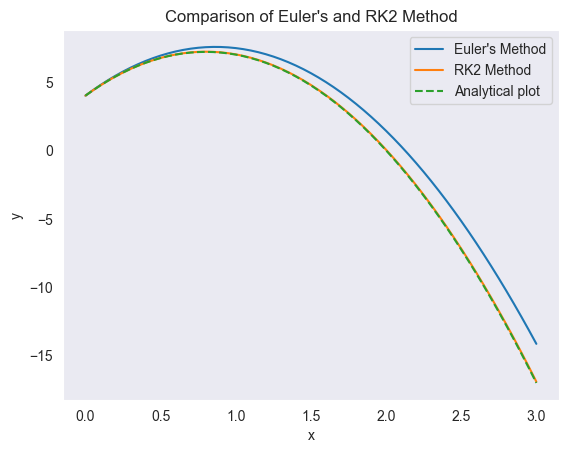

In [7]:
def Eul(f, x0, y0, h, N):
    x1 = np.linspace(x0, x0 + N * h, N + 1)
    y1 = np.zeros(N + 1)
    y1[0] = y0

    for i in range(N):
        y1[i + 1] = y1[i] + h * f(x1[i], y1[i])

    return x1, y1

def RK2(f, x0, y0, h, N):
    x1 = np.linspace(x0, x0 + N * h, N + 1)
    y1 = np.zeros(N + 1)
    y1[0] = y0

    for i in range(N):
      k1 = h*f(x1[i], y1[i])
      k2 = h*f(x1[i] + h, y1[i] + k1)
      y1[i+1] = y1[i] + (k1 + k2)/2

    return x1, y1

def f(x, y):
  return (2*y - 18*x)/(1 + x)

def af(x):
  return -5*x**2 + 8*x + 4

x, y  = Eul(f, 0, 4, 0.05, 60)
x1, y1 = RK2(f, 0, 4, 0.05, 60)

plt.plot(x, y, label = "Euler's Method")
plt.plot(x1, y1, label = "RK2 Method")
plt.plot(x, af(x), label = "Analytical plot", linestyle = "--")
plt.title("Comparison of Euler's and RK2 Method")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

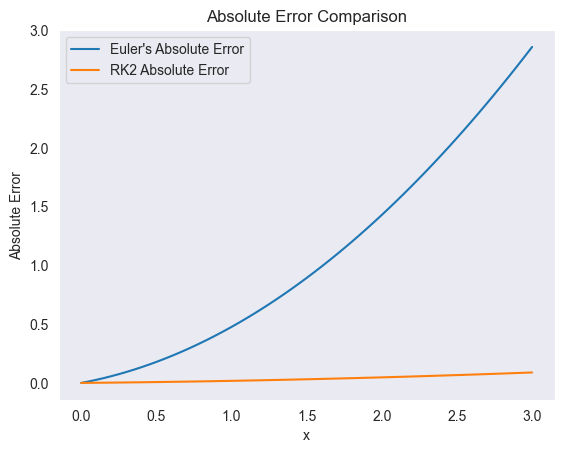

In [8]:
err = np.abs(af(x) - y)
err1 = np.abs(af(x1) - y1)
plt.plot(x, err, label = "Euler's Absolute Error")
plt.plot(x1, err1, label = "RK2 Absolute Error")
plt.title("Absolute Error Comparison")
plt.xlabel("x")
plt.ylabel("Absolute Error")
plt.legend()
plt.grid()
plt.show()

## P6

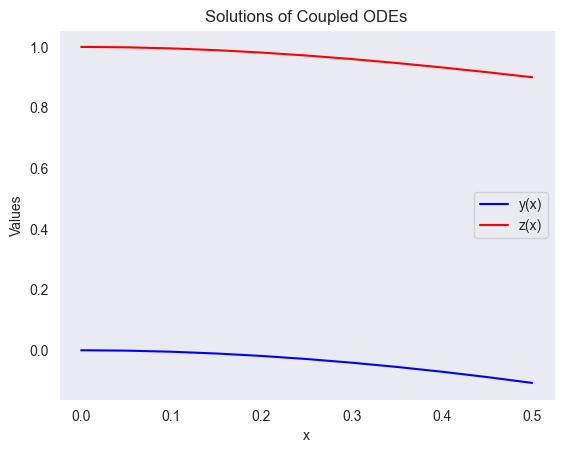

In [9]:
def Eul(f, x0, y0, h, N):
    x1 = np.linspace(x0, x0 + N * h, N + 1)
    y1 = np.zeros(N + 1)
    y1[0] = y0

    for i in range(N):
        y1[i + 1] = y1[i] + h * f(x1[i], y1[i])

    return x1, y1

def RK2(f, x0, y0, h, N):
    x1 = np.linspace(x0, x0 + N * h, N + 1)
    y1 = np.zeros((N + 1, 2))
    y1[0] = y0

    for i in range(N):
      k1 = h*f(x1[i], y1[i])
      k2 = h*f(x1[i] + h, y1[i] + k1)
      y1[i+1] = y1[i] + (k1 + k2)/2

    return x1, y1

def F(x, Y):
    y, z = Y
    dydx = -x - y * z
    dzdx = -y - x * z
    return np.array([dydx, dzdx])

x0, y0, z0 = 0, 0, 1
h, N = 0.05, 10

x, s = RK2(F, x0, [y0, z0], h, N)
y, z = s[:, 0], s[:, 1]

plt.plot(x, y, 'b-', label='y(x)')
plt.plot(x, z, 'r-', label='z(x)')
plt.xlabel('x')
plt.ylabel('Values')
plt.legend()
plt.title('Solutions of Coupled ODEs')
plt.grid()
plt.show()


## P7

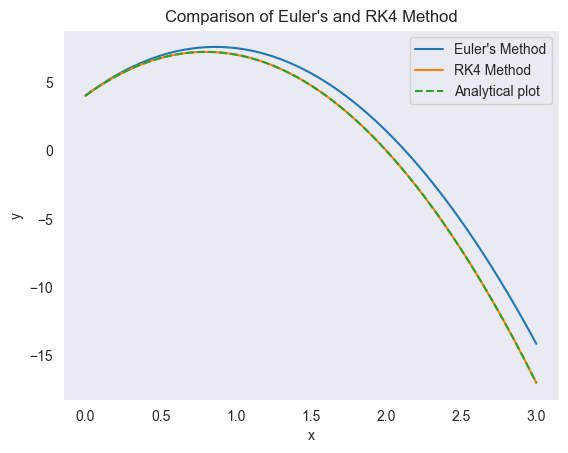

In [10]:
def f(x, y):
  return (2*y - 18*x)/(1 + x)

def af(x):
  return -5*x**2 + 8*x + 4

def Eul(f, x0, y0, h, N):
    x1 = np.linspace(x0, x0 + N * h, N + 1)
    y1 = np.zeros(N + 1)
    y1[0] = y0

    for i in range(N):
        y1[i + 1] = y1[i] + h * f(x1[i], y1[i])

    return x1, y1

def RK4(f, x0, y0, h, N):
    x = np.linspace(x0, x0 + N * h, N + 1)
    y = np.zeros(N + 1)
    y[0] = y0

    for i in range(N):
      k1 = h * f(x[i], y[i])
      k2 = h * f(x[i] + h/2, y[i] + k1/2)
      k3 = h * f(x[i] + h/2, y[i] + k2/2)
      k4 = h * f(x[i] + h, y[i] + k3)

      y[i+1] = y[i] + (k1 + 2*k2 + 2*k3 + k4)/6

    return x, y

x, y  = Eul(f, 0, 4, 0.05, 60)
x2, y2 = RK4(f, 0, 4, 0.05, 60)

plt.plot(x, y, label = "Euler's Method")
plt.plot(x2, y2, label = "RK4 Method")
plt.plot(x, af(x), label = "Analytical plot", linestyle = "--")
plt.title("Comparison of Euler's and RK4 Method")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

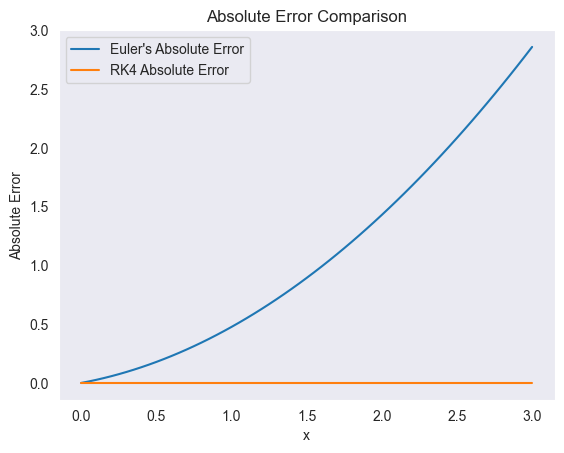

In [11]:
err = np.abs(af(x) - y)
err2 = np.abs(af(x2) - y2)
plt.plot(x, err, label = "Euler's Absolute Error")
plt.plot(x2, err2, label = "RK4 Absolute Error")
plt.title("Absolute Error Comparison")
plt.xlabel("x")
plt.ylabel("Absolute Error")
plt.legend()
plt.grid()
plt.show()